In [ ]:
# Step 1: Import Libraries and Create Multiclass Classification Dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import (SelectKBest, f_classif, chi2,
                                        mutual_info_classif, RFE,
                                        SelectFromModel)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore')

# Create multiclass classification dataset
np.random.seed(42)
X, y = make_classification(
    n_samples=1000,
    n_features=20,
    n_informative=15,
    n_redundant=5,
    n_classes=3,
    n_clusters_per_class=2,
    random_state=42
)

# Create DataFrame for better visualization
feature_names = [f'Feature_{i+1}' for i in range(X.shape[1])]
df = pd.DataFrame(X, columns=feature_names)
df['Target'] = y

print("Dataset Shape:", X.shape)
print("\nClass Distribution:")
print(pd.Series(y).value_counts().sort_index())
print("\nFirst 5 rows:")
print(df.head())
print("\nDataset Statistics:")
print(df.describe())

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"\nTraining set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Dataset Shape: (1000, 20)

Class Distribution:
0    333
1    331
2    336
Name: count, dtype: int64

First 5 rows:
   Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6  \
0  -0.901221   6.891120   0.781780   4.881550   5.346387  -2.085253   
1   0.072393   1.177955   3.577544   0.397404   1.892686  -0.722847   
2   1.471531  -0.041306   0.565783  -6.442122  -0.157103   0.350909   
3  -2.113880  -2.614208   6.021720  -3.606002  -0.220972   1.513633   
4  -2.545632   0.927238   5.898844   0.961911  -0.196116   0.147505   

   Feature_7  Feature_8  Feature_9  Feature_10  ...  Feature_12  Feature_13  \
0   2.541965   2.693544   0.057101    1.255127  ...   -0.393752    0.850942   
1   1.146988   0.361880   2.191223    1.289131  ...   -1.607681   -2.938141   
2  -0.126127  -1.113544   0.923643    0.667061  ...   -0.910122    3.968096   
3  -1.276867   0.405553   3.146789   -0.416216  ...   -4.797035   -2.893789   
4  -0.773266   3.050911   1.034188   -0.935489  ...    1.919454

FILTER METHOD: ANOVA F-test

Selected 10 features using Filter Method

Feature Importance Scores:
       Feature      Score Selected
6    Feature_7  78.636345      Yes
10  Feature_11  57.976981      Yes
3    Feature_4  49.128070      Yes
16  Feature_17  28.821208      Yes
1    Feature_2  27.120953      Yes
13  Feature_14  25.941403      Yes
15  Feature_16  22.519619      Yes
9   Feature_10  21.943071      Yes
14  Feature_15  21.769939      Yes
2    Feature_3  18.243455      Yes
12  Feature_13  14.956824       No
19  Feature_20  14.470991       No
4    Feature_5  11.790004       No
0    Feature_1  10.276633       No
17  Feature_18   8.293350       No
11  Feature_12   7.113104       No
18  Feature_19   1.195685       No
5    Feature_6   0.520584       No
8    Feature_9   0.172345       No
7    Feature_8   0.120449       No

Selected Features:
['Feature_2', 'Feature_3', 'Feature_4', 'Feature_7', 'Feature_10', 'Feature_11', 'Feature_14', 'Feature_15', 'Feature_16', 'Feature_17']


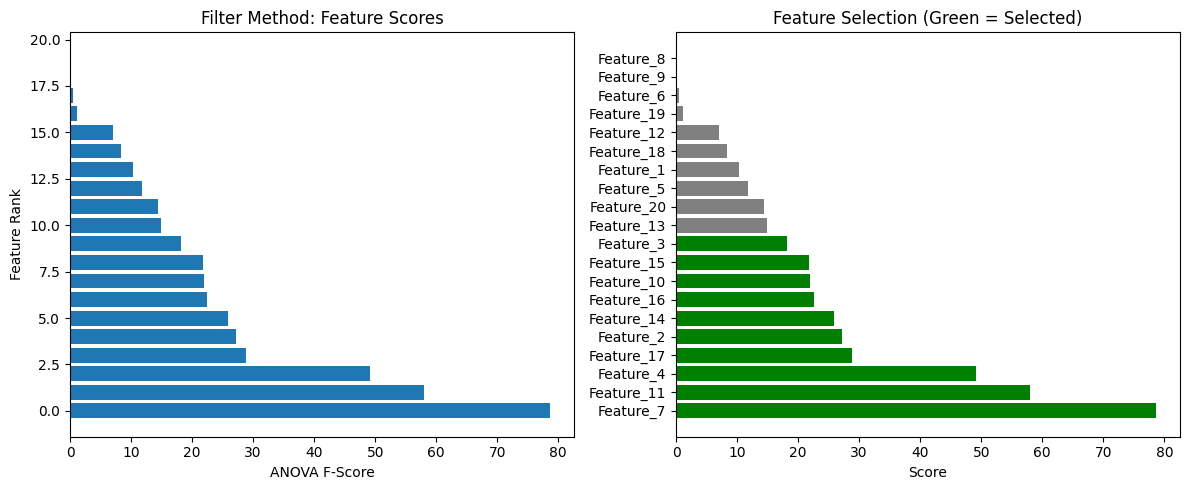

In [ ]:
# Step 2: Filter Method - ANOVA F-test (Best for multiclass classification)
print("="*60)
print("FILTER METHOD: ANOVA F-test")
print("="*60)

# Select top 10 features using ANOVA F-test
selector_filter = SelectKBest(score_func=f_classif, k=10)
X_train_filter = selector_filter.fit_transform(X_train, y_train)
X_test_filter = selector_filter.transform(X_test)

# Get selected feature indices and scores
selected_features_filter = selector_filter.get_support(indices=True)
feature_scores = selector_filter.scores_

print(f"\nSelected {X_train_filter.shape[1]} features using Filter Method")
print("\nFeature Importance Scores:")
score_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in range(len(feature_names))],
    'Score': feature_scores,
    'Selected': ['Yes' if i in selected_features_filter else 'No'
                 for i in range(len(feature_names))]
}).sort_values('Score', ascending=False)
print(score_df)

print("\nSelected Features:")
print([feature_names[i] for i in selected_features_filter])

# Visualize feature scores
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.barh(range(len(feature_scores)), sorted(feature_scores, reverse=True))
plt.xlabel('ANOVA F-Score')
plt.ylabel('Feature Rank')
plt.title('Filter Method: Feature Scores')
plt.subplot(1, 2, 2)
colors = ['green' if score_df.iloc[i]['Selected'] == 'Yes' else 'gray'
          for i in range(len(score_df))]
plt.barh(score_df['Feature'], score_df['Score'], color=colors)
plt.xlabel('Score')
plt.title('Feature Selection (Green = Selected)')
plt.tight_layout()
plt.show()

WRAPPER METHOD: Recursive Feature Elimination (RFE)

Selected 10 features using Wrapper Method

Feature Rankings (1 = selected):
       Feature  Ranking Selected
1    Feature_2        1      Yes
7    Feature_8        1      Yes
6    Feature_7        1      Yes
14  Feature_15        1      Yes
15  Feature_16        1      Yes
11  Feature_12        1      Yes
10  Feature_11        1      Yes
9   Feature_10        1      Yes
19  Feature_20        1      Yes
17  Feature_18        1      Yes
3    Feature_4        2       No
8    Feature_9        3       No
13  Feature_14        4       No
2    Feature_3        5       No
0    Feature_1        6       No
12  Feature_13        7       No
16  Feature_17        8       No
4    Feature_5        9       No
18  Feature_19       10       No
5    Feature_6       11       No

Selected Features:
['Feature_2', 'Feature_7', 'Feature_8', 'Feature_10', 'Feature_11', 'Feature_12', 'Feature_15', 'Feature_16', 'Feature_18', 'Feature_20']


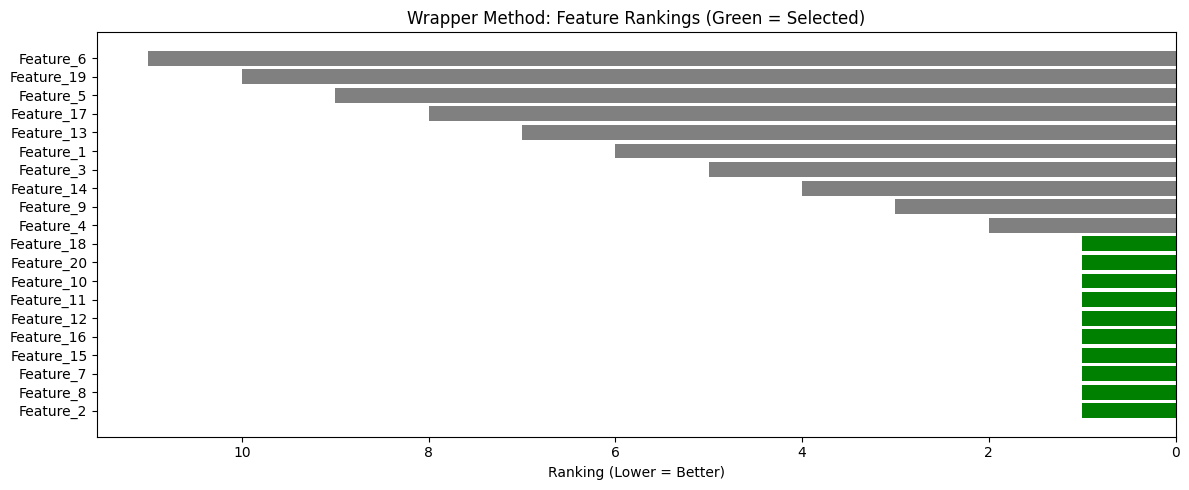

In [ ]:
# Step 3: Wrapper Method - Recursive Feature Elimination (RFE)
print("="*60)
print("WRAPPER METHOD: Recursive Feature Elimination (RFE)")
print("="*60)

# Use Logistic Regression as the estimator for RFE
estimator = LogisticRegression(max_iter=1000, random_state=42)
selector_wrapper = RFE(estimator=estimator, n_features_to_select=10, step=1)

X_train_wrapper = selector_wrapper.fit_transform(X_train, y_train)
X_test_wrapper = selector_wrapper.transform(X_test)

# Get selected features
selected_features_wrapper = selector_wrapper.get_support(indices=True)
feature_ranking = selector_wrapper.ranking_

print(f"\nSelected {X_train_wrapper.shape[1]} features using Wrapper Method")
print("\nFeature Rankings (1 = selected):")
ranking_df = pd.DataFrame({
    'Feature': feature_names,
    'Ranking': feature_ranking,
    'Selected': ['Yes' if i in selected_features_wrapper else 'No'
                 for i in range(len(feature_names))]
}).sort_values('Ranking')
print(ranking_df)

print("\nSelected Features:")
print([feature_names[i] for i in selected_features_wrapper])

# Visualize
plt.figure(figsize=(12, 5))
colors = ['green' if ranking_df.iloc[i]['Selected'] == 'Yes' else 'gray'
          for i in range(len(ranking_df))]
plt.barh(ranking_df['Feature'], ranking_df['Ranking'], color=colors)
plt.xlabel('Ranking (Lower = Better)')
plt.title('Wrapper Method: Feature Rankings (Green = Selected)')
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

EMBEDDED METHOD: Random Forest Feature Importance

Selected 7 features using Embedded Method

Feature Importances:
       Feature  Importance Selected
6    Feature_7    0.096424      Yes
10  Feature_11    0.064799      Yes
19  Feature_20    0.064692      Yes
3    Feature_4    0.059687      Yes
16  Feature_17    0.059582      Yes
2    Feature_3    0.052666      Yes
13  Feature_14    0.050904      Yes
9   Feature_10    0.049248       No
15  Feature_16    0.048332       No
0    Feature_1    0.047847       No
1    Feature_2    0.046524       No
7    Feature_8    0.045222       No
12  Feature_13    0.043703       No
14  Feature_15    0.042254       No
18  Feature_19    0.040671       No
17  Feature_18    0.040621       No
11  Feature_12    0.038620       No
4    Feature_5    0.036635       No
5    Feature_6    0.036399       No
8    Feature_9    0.035171       No

Selected Features:
['Feature_3', 'Feature_4', 'Feature_7', 'Feature_11', 'Feature_14', 'Feature_17', 'Feature_20']


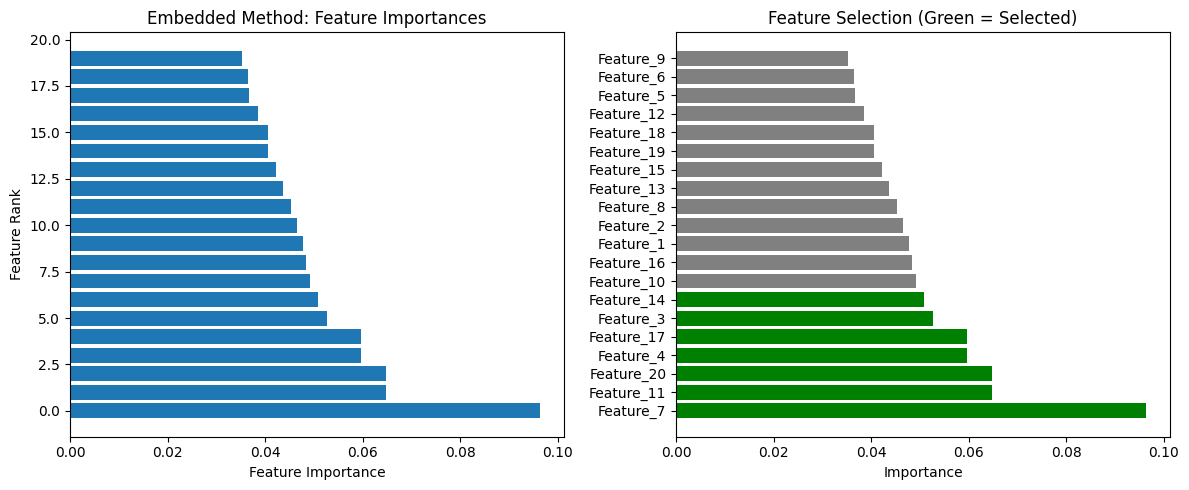

In [ ]:
# Step 4: Embedded Method - Random Forest Feature Importance
print("="*60)
print("EMBEDDED METHOD: Random Forest Feature Importance")
print("="*60)

# Train Random Forest and select features based on importance
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Get feature importances
feature_importances = rf_model.feature_importances_

# Select top 10 features
selector_embedded = SelectFromModel(rf_model, prefit=True, max_features=10)
X_train_embedded = selector_embedded.transform(X_train)
X_test_embedded = selector_embedded.transform(X_test)

selected_features_embedded = selector_embedded.get_support(indices=True)

print(f"\nSelected {X_train_embedded.shape[1]} features using Embedded Method")
print("\nFeature Importances:")
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances,
    'Selected': ['Yes' if i in selected_features_embedded else 'No'
                 for i in range(len(feature_names))]
}).sort_values('Importance', ascending=False)
print(importance_df)

print("\nSelected Features:")
print([feature_names[i] for i in selected_features_embedded])

# Visualize
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.barh(range(len(feature_importances)),
         sorted(feature_importances, reverse=True))
plt.xlabel('Feature Importance')
plt.ylabel('Feature Rank')
plt.title('Embedded Method: Feature Importances')
plt.subplot(1, 2, 2)
colors = ['green' if importance_df.iloc[i]['Selected'] == 'Yes' else 'gray'
          for i in range(len(importance_df))]
plt.barh(importance_df['Feature'], importance_df['Importance'], color=colors)
plt.xlabel('Importance')
plt.title('Feature Selection (Green = Selected)')
plt.tight_layout()
plt.show()

In [ ]:
# Step 5: Apply KNN and Logistic Regression on all three methods (Without PCA)
print("="*60)
print("MODEL EVALUATION WITHOUT PCA (k=10)")
print("="*60)

# Scale the data
scaler = StandardScaler()

# Dictionary to store results
results_without_pca = {}

# Prepare datasets
datasets = {
    'Filter': (X_train_filter, X_test_filter),
    'Wrapper': (X_train_wrapper, X_test_wrapper),
    'Embedded': (X_train_embedded, X_test_embedded)
}

for method_name, (X_tr, X_te) in datasets.items():
    print(f"\n{'='*60}")
    print(f"{method_name} Method")
    print(f"{'='*60}")

    # Scale data
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_te_scaled = scaler.transform(X_te)

    # KNN (k=10)
    knn = KNeighborsClassifier(n_neighbors=10)
    knn.fit(X_tr_scaled, y_train)
    y_pred_knn = knn.predict(X_te_scaled)
    knn_accuracy = accuracy_score(y_test, y_pred_knn)
    knn_cv_scores = cross_val_score(knn, X_tr_scaled, y_train, cv=5)

    print(f"\nKNN (k=10) Results:")
    print(f"Test Accuracy: {knn_accuracy:.4f}")
    print(f"Cross-Val Mean: {knn_cv_scores.mean():.4f} (+/- {knn_cv_scores.std():.4f})")

    # Logistic Regression
    lr = LogisticRegression(max_iter=1000, random_state=42)
    lr.fit(X_tr_scaled, y_train)
    y_pred_lr = lr.predict(X_te_scaled)
    lr_accuracy = accuracy_score(y_test, y_pred_lr)
    lr_cv_scores = cross_val_score(lr, X_tr_scaled, y_train, cv=5)

    print(f"\nLogistic Regression Results:")
    print(f"Test Accuracy: {lr_accuracy:.4f}")
    print(f"Cross-Val Mean: {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})")

    # Store results
    results_without_pca[method_name] = {
        'KNN': {
            'accuracy': knn_accuracy,
            'cv_mean': knn_cv_scores.mean(),
            'cv_std': knn_cv_scores.std()
        },
        'LR': {
            'accuracy': lr_accuracy,
            'cv_mean': lr_cv_scores.mean(),
            'cv_std': lr_cv_scores.std()
        }
    }

print("\n" + "="*60)
print("SUMMARY: Results Without PCA")
print("="*60)
for method in results_without_pca:
    print(f"\n{method}:")
    print(f"  KNN: {results_without_pca[method]['KNN']['accuracy']:.4f}")
    print(f"  LR:  {results_without_pca[method]['LR']['accuracy']:.4f}")

MODEL EVALUATION WITHOUT PCA (k=10)

Filter Method

KNN (k=10) Results:
Test Accuracy: 0.6867
Cross-Val Mean: 0.7114 (+/- 0.0337)

Logistic Regression Results:
Test Accuracy: 0.6367
Cross-Val Mean: 0.6514 (+/- 0.0345)

Wrapper Method

KNN (k=10) Results:
Test Accuracy: 0.7400
Cross-Val Mean: 0.7343 (+/- 0.0408)

Logistic Regression Results:
Test Accuracy: 0.6967
Cross-Val Mean: 0.6814 (+/- 0.0147)

Embedded Method

KNN (k=10) Results:
Test Accuracy: 0.6833
Cross-Val Mean: 0.7143 (+/- 0.0373)

Logistic Regression Results:
Test Accuracy: 0.6400
Cross-Val Mean: 0.6500 (+/- 0.0120)

SUMMARY: Results Without PCA

Filter:
  KNN: 0.6867
  LR:  0.6367

Wrapper:
  KNN: 0.7400
  LR:  0.6967

Embedded:
  KNN: 0.6833
  LR:  0.6400


APPLYING PCA TO ALL THREE METHODS

Filter Method:
  Original shape: (700, 10)
  PCA shape: (700, 10)
  Explained variance ratio: 1.0000
  Components: [0.21170476 0.1877976  0.15758651 0.1236137  0.11211147]

Wrapper Method:
  Original shape: (700, 10)
  PCA shape: (700, 10)
  Explained variance ratio: 1.0000
  Components: [0.18538226 0.14924972 0.1310097  0.11143137 0.09734304]

Embedded Method:
  Original shape: (700, 7)
  PCA shape: (700, 7)
  Explained variance ratio: 1.0000
  Components: [0.26745697 0.23293826 0.20005167 0.12439922 0.09266919]


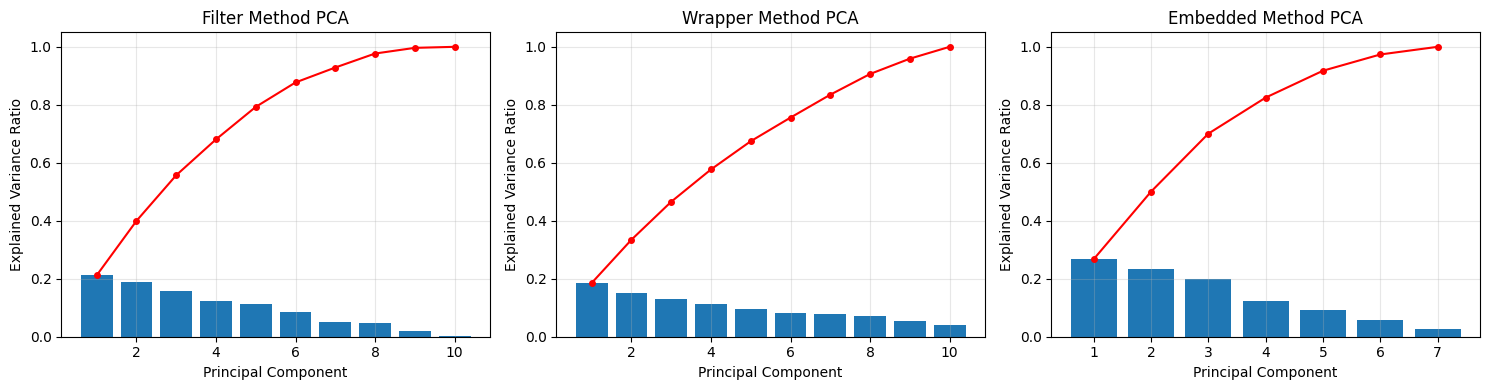


PCA transformation completed for all methods!


In [ ]:
# Step 6: Apply PCA on all three methods
print("="*60)
print("APPLYING PCA TO ALL THREE METHODS")
print("="*60)

# Apply PCA with same number of components as selected features
pca_datasets = {}

for method_name, (X_tr, X_te) in datasets.items():
    print(f"\n{method_name} Method:")

    # Scale data first
    scaler_pca = StandardScaler()
    X_tr_scaled = scaler_pca.fit_transform(X_tr)
    X_te_scaled = scaler_pca.transform(X_te)

    # Apply PCA
    n_components = min(10, X_tr.shape[1])
    pca = PCA(n_components=n_components)
    X_tr_pca = pca.fit_transform(X_tr_scaled)
    X_te_pca = pca.transform(X_te_scaled)

    pca_datasets[method_name] = (X_tr_pca, X_te_pca)

    print(f"  Original shape: {X_tr.shape}")
    print(f"  PCA shape: {X_tr_pca.shape}")
    print(f"  Explained variance ratio: {pca.explained_variance_ratio_.sum():.4f}")
    print(f"  Components: {pca.explained_variance_ratio_[:5]}")

# Visualize explained variance
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, (method_name, (X_tr, X_te)) in enumerate(datasets.items()):
    scaler_pca = StandardScaler()
    X_tr_scaled = scaler_pca.fit_transform(X_tr)
    n_components = min(10, X_tr.shape[1])
    pca = PCA(n_components=n_components)
    pca.fit(X_tr_scaled)

    axes[idx].bar(range(1, len(pca.explained_variance_ratio_) + 1),
                  pca.explained_variance_ratio_)
    axes[idx].plot(range(1, len(pca.explained_variance_ratio_) + 1),
                   np.cumsum(pca.explained_variance_ratio_),
                   'r-o', markersize=4)
    axes[idx].set_xlabel('Principal Component')
    axes[idx].set_ylabel('Explained Variance Ratio')
    axes[idx].set_title(f'{method_name} Method PCA')
    axes[idx].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nPCA transformation completed for all methods!")

In [ ]:
# Step 7: Apply KNN and Logistic Regression on PCA-transformed data
print("="*60)
print("MODEL EVALUATION WITH PCA (k=10)")
print("="*60)

# Dictionary to store results
results_with_pca = {}

for method_name, (X_tr_pca, X_te_pca) in pca_datasets.items():
    print(f"\n{'='*60}")
    print(f"{method_name} Method (with PCA)")
    print(f"{'='*60}")

    # KNN (k=10)
    knn = KNeighborsClassifier(n_neighbors=10)
    knn.fit(X_tr_pca, y_train)
    y_pred_knn = knn.predict(X_te_pca)
    knn_accuracy = accuracy_score(y_test, y_pred_knn)
    knn_cv_scores = cross_val_score(knn, X_tr_pca, y_train, cv=5)

    print(f"\nKNN (k=10) Results:")
    print(f"Test Accuracy: {knn_accuracy:.4f}")
    print(f"Cross-Val Mean: {knn_cv_scores.mean():.4f} (+/- {knn_cv_scores.std():.4f})")

    # Logistic Regression
    lr = LogisticRegression(max_iter=1000, random_state=42)
    lr.fit(X_tr_pca, y_train)
    y_pred_lr = lr.predict(X_te_pca)
    lr_accuracy = accuracy_score(y_test, y_pred_lr)
    lr_cv_scores = cross_val_score(lr, X_tr_pca, y_train, cv=5)

    print(f"\nLogistic Regression Results:")
    print(f"Test Accuracy: {lr_accuracy:.4f}")
    print(f"Cross-Val Mean: {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})")

    # Store results
    results_with_pca[method_name] = {
        'KNN': {
            'accuracy': knn_accuracy,
            'cv_mean': knn_cv_scores.mean(),
            'cv_std': knn_cv_scores.std()
        },
        'LR': {
            'accuracy': lr_accuracy,
            'cv_mean': lr_cv_scores.mean(),
            'cv_std': lr_cv_scores.std()
        }
    }

print("\n" + "="*60)
print("SUMMARY: Results With PCA")
print("="*60)
for method in results_with_pca:
    print(f"\n{method}:")
    print(f"  KNN: {results_with_pca[method]['KNN']['accuracy']:.4f}")
    print(f"  LR:  {results_with_pca[method]['LR']['accuracy']:.4f}")

MODEL EVALUATION WITH PCA (k=10)

Filter Method (with PCA)

KNN (k=10) Results:
Test Accuracy: 0.6867
Cross-Val Mean: 0.7114 (+/- 0.0337)

Logistic Regression Results:
Test Accuracy: 0.6367
Cross-Val Mean: 0.6514 (+/- 0.0345)

Wrapper Method (with PCA)

KNN (k=10) Results:
Test Accuracy: 0.7400
Cross-Val Mean: 0.7343 (+/- 0.0408)

Logistic Regression Results:
Test Accuracy: 0.6967
Cross-Val Mean: 0.6814 (+/- 0.0147)

Embedded Method (with PCA)

KNN (k=10) Results:
Test Accuracy: 0.6833
Cross-Val Mean: 0.7143 (+/- 0.0373)

Logistic Regression Results:
Test Accuracy: 0.6400
Cross-Val Mean: 0.6500 (+/- 0.0120)

SUMMARY: Results With PCA

Filter:
  KNN: 0.6867
  LR:  0.6367

Wrapper:
  KNN: 0.7400
  LR:  0.6967

Embedded:
  KNN: 0.6833
  LR:  0.6400


In [ ]:
# Step 8: Comprehensive Comparison (Like your sample documentation)
print("="*80)
print("COMPREHENSIVE COMPARISON: WITH PCA vs WITHOUT PCA")
print("="*80)

# Create comparison dataframe
comparison_data = []

for method in ['Filter', 'Wrapper', 'Embedded']:
    for model in ['KNN', 'LR']:
        comparison_data.append({
            'Feature Selection': method,
            'Model': model,
            'Without PCA': results_without_pca[method][model]['accuracy'],
            'With PCA': results_with_pca[method][model]['accuracy'],
            'Difference': results_with_pca[method][model]['accuracy'] -
                         results_without_pca[method][model]['accuracy']
        })

comparison_df = pd.DataFrame(comparison_data)
print("\n" + "="*80)
print("ACCURACY COMPARISON TABLE")
print("="*80)
print(comparison_df.to_string(index=False))

# Calculate consistency metrics
print("\n" + "="*80)
print("CONSISTENCY ANALYSIS")
print("="*80)

consistency_metrics = []
for method in ['Filter', 'Wrapper', 'Embedded']:
    without_pca_scores = [
        results_without_pca[method]['KNN']['accuracy'],
        results_without_pca[method]['LR']['accuracy']
    ]
    with_pca_scores = [
        results_with_pca[method]['KNN']['accuracy'],
        results_with_pca[method]['LR']['accuracy']
    ]

    consistency_metrics.append({
        'Method': method,
        'Without PCA Mean': np.mean(without_pca_scores),
        'Without PCA Std': np.std(without_pca_scores),
        'With PCA Mean': np.mean(with_pca_scores),
        'With PCA Std': np.std(with_pca_scores),
        'More Consistent': 'With PCA' if np.std(with_pca_scores) < np.std(without_pca_scores) else 'Without PCA'
    })

consistency_df = pd.DataFrame(consistency_metrics)
print(consistency_df.to_string(index=False))

# Overall best method
print("\n" + "="*80)
print("OVERALL BEST PERFORMANCE")
print("="*80)

best_without_pca = comparison_df.loc[comparison_df['Without PCA'].idxmax()]
best_with_pca = comparison_df.loc[comparison_df['With PCA'].idxmax()]

print(f"\nBest WITHOUT PCA:")
print(f"  Method: {best_without_pca['Feature Selection']}")
print(f"  Model: {best_without_pca['Model']}")
print(f"  Accuracy: {best_without_pca['Without PCA']:.4f}")

print(f"\nBest WITH PCA:")
print(f"  Method: {best_with_pca['Feature Selection']}")
print(f"  Model: {best_with_pca['Model']}")
print(f"  Accuracy: {best_with_pca['With PCA']:.4f}")

# Find most consistent method
most_consistent = consistency_df.loc[consistency_df['With PCA Std'].idxmin()]
print(f"\nMost Consistent Method: {most_consistent['Method']}")
print(f"  Standard Deviation with PCA: {most_consistent['With PCA Std']:.4f}")

COMPREHENSIVE COMPARISON: WITH PCA vs WITHOUT PCA

ACCURACY COMPARISON TABLE
Feature Selection Model  Without PCA  With PCA  Difference
           Filter   KNN     0.686667  0.686667         0.0
           Filter    LR     0.636667  0.636667         0.0
          Wrapper   KNN     0.740000  0.740000         0.0
          Wrapper    LR     0.696667  0.696667         0.0
         Embedded   KNN     0.683333  0.683333         0.0
         Embedded    LR     0.640000  0.640000         0.0

CONSISTENCY ANALYSIS
  Method  Without PCA Mean  Without PCA Std  With PCA Mean  With PCA Std More Consistent
  Filter          0.661667         0.025000       0.661667      0.025000     Without PCA
 Wrapper          0.718333         0.021667       0.718333      0.021667     Without PCA
Embedded          0.661667         0.021667       0.661667      0.021667     Without PCA

OVERALL BEST PERFORMANCE

Best WITHOUT PCA:
  Method: Wrapper
  Model: KNN
  Accuracy: 0.7400

Best WITH PCA:
  Method: Wrapper
  M

GENERATING COMPARISON VISUALIZATIONS


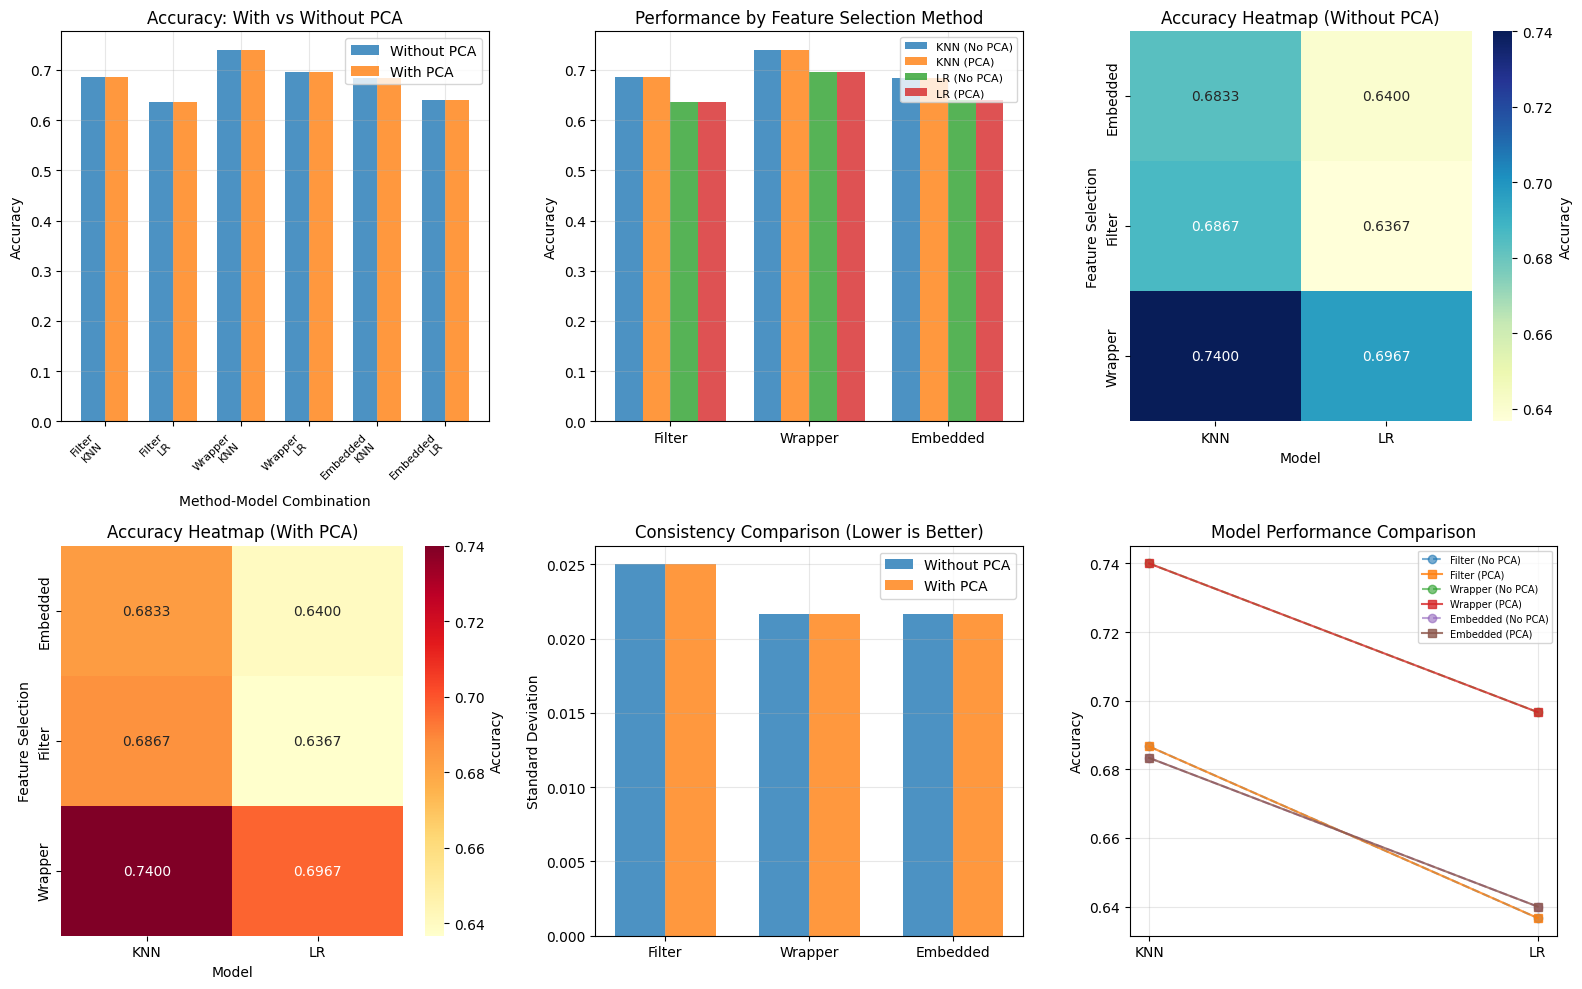


Visualization complete!


In [ ]:
# Step 9: Visualizations for Comparison
print("="*80)
print("GENERATING COMPARISON VISUALIZATIONS")
print("="*80)

# Create comprehensive visualization
fig = plt.figure(figsize=(16, 10))

# 1. Bar plot: Accuracy comparison
ax1 = plt.subplot(2, 3, 1)
x = np.arange(len(comparison_df))
width = 0.35
bars1 = ax1.bar(x - width/2, comparison_df['Without PCA'], width,
                label='Without PCA', alpha=0.8)
bars2 = ax1.bar(x + width/2, comparison_df['With PCA'], width,
                label='With PCA', alpha=0.8)
ax1.set_xlabel('Method-Model Combination')
ax1.set_ylabel('Accuracy')
ax1.set_title('Accuracy: With vs Without PCA')
ax1.set_xticks(x)
ax1.set_xticklabels([f"{row['Feature Selection']}\n{row['Model']}"
                      for _, row in comparison_df.iterrows()],
                     rotation=45, ha='right', fontsize=8)
ax1.legend()
ax1.grid(alpha=0.3)

# 2. Grouped bar chart by method
ax2 = plt.subplot(2, 3, 2)
methods = ['Filter', 'Wrapper', 'Embedded']
knn_without = [results_without_pca[m]['KNN']['accuracy'] for m in methods]
knn_with = [results_with_pca[m]['KNN']['accuracy'] for m in methods]
lr_without = [results_without_pca[m]['LR']['accuracy'] for m in methods]
lr_with = [results_with_pca[m]['LR']['accuracy'] for m in methods]

x = np.arange(len(methods))
width = 0.2
ax2.bar(x - 1.5*width, knn_without, width, label='KNN (No PCA)', alpha=0.8)
ax2.bar(x - 0.5*width, knn_with, width, label='KNN (PCA)', alpha=0.8)
ax2.bar(x + 0.5*width, lr_without, width, label='LR (No PCA)', alpha=0.8)
ax2.bar(x + 1.5*width, lr_with, width, label='LR (PCA)', alpha=0.8)
ax2.set_ylabel('Accuracy')
ax2.set_title('Performance by Feature Selection Method')
ax2.set_xticks(x)
ax2.set_xticklabels(methods)
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

# 3. Heatmap of accuracies
ax3 = plt.subplot(2, 3, 3)
heatmap_data = comparison_df.pivot_table(
    values='Without PCA',
    index='Feature Selection',
    columns='Model'
)
sns.heatmap(heatmap_data, annot=True, fmt='.4f', cmap='YlGnBu',
            ax=ax3, cbar_kws={'label': 'Accuracy'})
ax3.set_title('Accuracy Heatmap (Without PCA)')

# 4. Heatmap with PCA
ax4 = plt.subplot(2, 3, 4)
heatmap_data_pca = comparison_df.pivot_table(
    values='With PCA',
    index='Feature Selection',
    columns='Model'
)
sns.heatmap(heatmap_data_pca, annot=True, fmt='.4f', cmap='YlOrRd',
            ax=ax4, cbar_kws={'label': 'Accuracy'})
ax4.set_title('Accuracy Heatmap (With PCA)')

# 5. Consistency comparison
ax5 = plt.subplot(2, 3, 5)
x = np.arange(len(methods))
width = 0.35
ax5.bar(x - width/2, consistency_df['Without PCA Std'], width,
        label='Without PCA', alpha=0.8)
ax5.bar(x + width/2, consistency_df['With PCA Std'], width,
        label='With PCA', alpha=0.8)
ax5.set_ylabel('Standard Deviation')
ax5.set_title('Consistency Comparison (Lower is Better)')
ax5.set_xticks(x)
ax5.set_xticklabels(methods)
ax5.legend()
ax5.grid(alpha=0.3)

# 6. Line plot showing improvement
ax6 = plt.subplot(2, 3, 6)
for method in methods:
    without = [results_without_pca[method]['KNN']['accuracy'],
               results_without_pca[method]['LR']['accuracy']]
    with_pca = [results_with_pca[method]['KNN']['accuracy'],
                results_with_pca[method]['LR']['accuracy']]
    ax6.plot(['KNN', 'LR'], without, 'o--', label=f'{method} (No PCA)', alpha=0.6)
    ax6.plot(['KNN', 'LR'], with_pca, 's-', label=f'{method} (PCA)', alpha=0.8)
ax6.set_ylabel('Accuracy')
ax6.set_title('Model Performance Comparison')
ax6.legend(fontsize=7, loc='best')
ax6.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nVisualization complete!")

In [ ]:
# Step 10: Generate Final Summary Report (Similar to your documentation format)
print("="*80)
print("FINAL SUMMARY REPORT")
print("="*80)

print("\n" + "="*80)
print("1. DATASET INFORMATION")
print("="*80)
print(f"Total Samples: {len(X)}")
print(f"Total Features: {X.shape[1]}")
print(f"Number of Classes: {len(np.unique(y))}")
print(f"Training Samples: {len(X_train)}")
print(f"Testing Samples: {len(X_test)}")
print(f"Features Selected: 10 (k=10)")

print("\n" + "="*80)
print("2. FEATURE SELECTION METHODS USED")
print("="*80)
print("a) Filter Method: ANOVA F-test")
print("   - Selects features based on statistical tests")
print("   - Fast and computationally efficient")
print(f"   - Selected features: {len(selected_features_filter)}")

print("\nb) Wrapper Method: Recursive Feature Elimination (RFE)")
print("   - Uses model performance to select features")
print("   - More computationally expensive but considers feature interactions")
print(f"   - Selected features: {len(selected_features_wrapper)}")

print("\nc) Embedded Method: Random Forest Feature Importance")
print("   - Feature selection during model training")
print("   - Balances performance and computational cost")
print(f"   - Selected features: {len(selected_features_embedded)}")

print("\n" + "="*80)
print("3. MODELS EVALUATED")
print("="*80)
print("a) K-Nearest Neighbors (KNN) with k=10")
print("b) Logistic Regression")

print("\n" + "="*80)
print("4. PERFORMANCE COMPARISON TABLE")
print("="*80)
print(comparison_df.to_string(index=False))

print("\n" + "="*80)
print("5. CONSISTENCY METRICS")
print("="*80)
print(consistency_df.to_string(index=False))

print("\n" + "="*80)
print("6. KEY OBSERVATIONS")
print("="*80)

# Calculate improvements
improvements = []
for method in ['Filter', 'Wrapper', 'Embedded']:
    for model in ['KNN', 'LR']:
        diff = results_with_pca[method][model]['accuracy'] - results_without_pca[method][model]['accuracy']
        improvements.append({
            'method': method,
            'model': model,
            'improvement': diff
        })

avg_improvement = np.mean([x['improvement'] for x in improvements])
positive_improvements = sum(1 for x in improvements if x['improvement'] > 0)

print(f"\na) Average accuracy change with PCA: {avg_improvement:+.4f}")
print(f"b) Number of cases where PCA improved performance: {positive_improvements}/{len(improvements)}")
print(f"c) Best overall accuracy: {comparison_df[['Without PCA', 'With PCA']].max().max():.4f}")
print(f"d) Most consistent method: {most_consistent['Method']}")

# Determine which is better
if avg_improvement > 0:
    print(f"\ne) PCA generally IMPROVED performance (avg: {avg_improvement:+.4f})")
else:
    print(f"\ne) PCA generally DECREASED performance (avg: {avg_improvement:+.4f})")

print("\n" + "="*80)
print("7. CONCLUSION")
print("="*80)
print(f"\nBased on the analysis of three feature selection methods (Filter, Wrapper,")
print(f"and Embedded) combined with two classifiers (KNN with k=10 and Logistic")
print(f"Regression), both with and without PCA:")

# Find best configuration
best_row = comparison_df.loc[comparison_df[['Without PCA', 'With PCA']].max(axis=1).idxmax()]
best_score = max(best_row['Without PCA'], best_row['With PCA'])
best_pca = 'with PCA' if best_row['With PCA'] > best_row['Without PCA'] else 'without PCA'

print(f"\n• BEST CONFIGURATION: {best_row['Feature Selection']} method + {best_row['Model']} {best_pca}")
print(f"  Accuracy: {best_score:.4f}")

print(f"\n• MOST CONSISTENT: {most_consistent['Method']} method")
print(f"  Standard Deviation: {most_consistent['With PCA Std']:.4f}")

print(f"\n• PCA IMPACT: ", end="")
if avg_improvement > 0.001:
    print(f"PCA improved average accuracy by {avg_improvement:.4f}")
elif avg_improvement < -0.001:
    print(f"PCA decreased average accuracy by {abs(avg_improvement):.4f}")
else:
    print("PCA had minimal impact on accuracy")

print(f"\n• RECOMMENDATION: ", end="")
if most_consistent['With PCA Std'] < most_consistent['Without PCA Std']:
    print(f"Use PCA for more consistent results across models")
else:
    print(f"Original features provide better consistency")

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)

FINAL SUMMARY REPORT

1. DATASET INFORMATION
Total Samples: 1000
Total Features: 20
Number of Classes: 3
Training Samples: 700
Testing Samples: 300
Features Selected: 10 (k=10)

2. FEATURE SELECTION METHODS USED
a) Filter Method: ANOVA F-test
   - Selects features based on statistical tests
   - Fast and computationally efficient
   - Selected features: 10

b) Wrapper Method: Recursive Feature Elimination (RFE)
   - Uses model performance to select features
   - More computationally expensive but considers feature interactions
   - Selected features: 10

c) Embedded Method: Random Forest Feature Importance
   - Feature selection during model training
   - Balances performance and computational cost
   - Selected features: 7

3. MODELS EVALUATED
a) K-Nearest Neighbors (KNN) with k=10
b) Logistic Regression

4. PERFORMANCE COMPARISON TABLE
Feature Selection Model  Without PCA  With PCA  Difference
           Filter   KNN     0.686667  0.686667         0.0
           Filter    LR     0.63